In [1]:
from pathlib import Path
import tkinter as tk
from tkinter import filedialog
import pandas as pd

root = tk.Tk()
# root.withdraw()
filename = filedialog.askopenfilename(
    title="Select daily production Parquet file",
    filetypes=[("Parquet files", "*.parquet *.pq"), ("All files", "*.*")],
)
root.destroy()

if not filename:
    raise FileNotFoundError("No daily production file was selected.")

dataset_path = Path(filename)
if dataset_path.suffix.lower() not in {".parquet", ".pq"}:
    raise ValueError("The selected file must be a Parquet file.")

daily_production = pd.read_parquet(dataset_path)
daily_production.head(10)

,uwi,formatted_uwi,well_name,field_operating_area,province,surface_latitude,surface_longitude,on_production_date,facility_name,well_daily_status,...,choke_open_pct,pcp_pump_name,pcp_pump_make,pcp_pump_model,pcp_pump_displacement_m3d100rpm,pcp_pump_rpm,pcp_pump_comment,pcp_pump_electric_current_a,pcp_pump_rod_torque_ftlb,pcp_pump_volume_throughput_m3d
0,100142303701W400,100/14-23-037-01W4/00,100/14-23-037-01W4/00,Bodo East,AB,52.1963470,-110.0553380,2018-10-02,None,Producing,...,NaN,None,None,None,NaN,None,None,NaN,NaN,NaN
1,141092703528W300,141/09-27-035-28W3/00,141/09-27-035-28W3/00 INJ,Cactus Lake,SK,52.0367781,-109.9092225,1980-07-19,Cactus EOR 12-21 Polymer Injection,Injecting,...,100.0,None,None,None,NaN,None,None,NaN,NaN,NaN
2,111152503528W300,111/15-25-035-28W3/00,(15A15-25) - 111/15-25-035-28W3/00,Cactus Lake,SK,52.0397797,-109.8680742,2014-08-24,Cactus Lake 16-27-035-28W3 BTY,Producing,...,NaN,111/15-25/00 PCP Pump,MANTL,6M-1800,6.0,385,None,NaN,NaN,23.1
3,192031104225W300,192/03-11-042-25W3/00,(12D14-11) - 192/03-11-042-25W3/00,Winter,SK,52.6090814,-109.4933142,1999-10-30,12-32 BTY Facility,Producing,...,NaN,(12D14-11) PCP Pump,MANTL,102-900,102.0,355,None,50.0,660.0000,362.1
4,191063103527W300,191/06-31-035-27W3/00,(4B06-31) - 191/06-31-035-27W3/00,Cactus Lake,SK,52.0466803,-109.8507078,2015-12-23,Cactus Lake 16-27-035-28W3 BTY,Suspended,...,NaN,191/06-31/00 PCP Pump,MANTL,127-M1200,127.0,270,None,NaN,NaN,342.9
5,191092704125W300,191/09-27-041-25W3/00,(8B02-34) - 191/09-27-041-25W3/00,Winter,SK,52.5669875,-109.5149864,2015-07-24,12-32 BTY Facility,Producing,...,NaN,(8B02-34) PCP Pump,Weatherford,106-1200,106.0,425,None,74.0,740.0000,450.5
6,111010503526W300,111/01-05-035-26W3/00,(A01-05) - 111/01-05-035-26W3/00 INJ,Plover Lake Conventional,SK,51.9699639,-109.6708033,None,PLOVER LAKE SWD A11-5-035-26W3,Injecting,...,NaN,None,None,None,NaN,None,None,NaN,NaN,NaN
7,121120603526W300,121/12-06-035-26W3/00,121/12-06-035-26W3/00,Plover Lake Conventional,SK,51.9771714,-109.7151739,1997-06-23,WAS NORCEN PLOVER LK B12-6,Suspended,...,NaN,None,None,None,NaN,None,None,NaN,NaN,NaN
8,106052704225W300,106/05-27-042-25W3/00,(8D06-27) - 106/05-27-042-25W3/00,Winter,SK,52.6457303,-109.5171839,2017-02-01,12-32 BTY Facility,Producing,...,NaN,(8D06-27) PCP Pump,BMW Pump,56-1200,56.0,55,2018-Jun-02,37.0,2507.7113,30.8
9,191132703420W300,191/13-27-034-20W3/00,191/13-27-034-20W3/00,Druid Main,SK,51.9449597,-108.7634600,2014-08-17,None,Producing,...,NaN,None,None,None,NaN,None,None,NaN,NaN,NaN


In [2]:
# remove unimportant columns
daily_production.drop(columns=[
"formatted_uwi", "well_name", "well_status", "pcp_pump_name", "pcp_pump_make", "pcp_pump_model", "pcp_pump_comment",
"downtime_code_1",  "facility_name", "tubing_pressure_kpa", "hydraulic_pressure_psi", "choke_open_pct", "hours_on_prod"
], inplace=True)

In [3]:
daily_production.columns

Index(['uwi', 'field_operating_area', 'province', 'surface_latitude',
       'surface_longitude', 'on_production_date', 'well_daily_status',
       'primary_fluid_type', 'flow_direction', 'production_date', 'hours_down',
       'lost_oil_m3', 'downtime_code_2', 'downtime_code_3',
       'casing_pressure_kpa', 'injection_pressure_kpa', 'oil_produced_m3',
       'gas_produced_e3m3', 'injection_volume_m3', 'injected_water_m3',
       'injected_polymer_m3', 'pump_efficiency_pct', 'water_produced_m3',
       'pcp_pump_displacement_m3d100rpm', 'pcp_pump_rpm',
       'pcp_pump_electric_current_a', 'pcp_pump_rod_torque_ftlb',
       'pcp_pump_volume_throughput_m3d'],
      dtype='object')

In [4]:
daily_production_for_encoding = daily_production.drop(columns=["uwi", "field_operating_area", "province", "production_date", "on_production_date"])

In [5]:

daily_production_encoded = pd.get_dummies(daily_production_for_encoding, columns=["well_daily_status", "primary_fluid_type", "flow_direction", "downtime_code_2", "downtime_code_3"], dtype="uint8")
daily_production_encoded.columns


Index(['surface_latitude', 'surface_longitude', 'hours_down', 'lost_oil_m3',
       'casing_pressure_kpa', 'injection_pressure_kpa', 'oil_produced_m3',
       'gas_produced_e3m3', 'injection_volume_m3', 'injected_water_m3',
       ...
       'downtime_code_3_Water Source Supply', 'downtime_code_3_Waxed Up',
       'downtime_code_3_Weather Conditions', 'downtime_code_3_Well Loaded',
       'downtime_code_3_Well Optimization/Stimulation',
       'downtime_code_3_Well Stimulation', 'downtime_code_3_Well Torqued',
       'downtime_code_3_Wellhead Drive/Stuffing',
       'downtime_code_3_Wellhead Drive/Stuffing Box',
       'downtime_code_3_Workover'],
      dtype='object', length=237)

## PCA pipeline and diagnostics

This section standardizes the numeric features, imputes missing values, and uses PCA for dimensionality reduction and contribution analysis.

In [6]:
# PCA setup
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Use only numeric columns. get_dummies should produce numeric columns, but this also
# protects PCA from any remaining text/category fields.
pca_data = daily_production_encoded.select_dtypes(include="number").copy()

# Remove constant columns: they have no variance and therefore contribute nothing to PCA.
constant_columns = pca_data.columns[pca_data.nunique(dropna=True) <= 1]
pca_data = pca_data.drop(columns=constant_columns)

print(f"Rows: {len(pca_data):,}")
print(f"Numeric, non-constant features: {pca_data.shape[1]:,}")
print(f"Missing values: {int(pca_data.isna().sum().sum())}")


Rows: 5,075,590
Numeric, non-constant features: 234
Missing values: 42411548


In [7]:
# A large dataframe can make exact, dense PCA expensive. Use a reproducible sample
# for PCA exploratory analysis, while keeping the final pipeline easy to reuse on
# other subsets or batches of the same data.
PCA_SAMPLE_SIZE = 100_000
analysis_sample = pca_data.sample(
    n=min(PCA_SAMPLE_SIZE, len(pca_data)),
    random_state=42,
)

# Keep enough components for a useful scree plot. The upper bound is also valid
# for the randomized solver used below.
explained_component_limit = min(
    50,
    analysis_sample.shape[0] - 1,
    analysis_sample.shape[1],
)

exploration_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("pca", PCA(
        n_components=explained_component_limit,
        svd_solver="randomized",
        random_state=42,
    )),
])

X_exploration = exploration_pipeline.fit_transform(analysis_sample)
exploration_pca = exploration_pipeline.named_steps["pca"]
explained_variance = exploration_pca.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

print(f"Analyzed sample size: {len(analysis_sample):,}")
print(f"Components plotted: {len(explained_variance)}")
print(f"Variance explained in the plotted components: {cumulative_variance[-1]:.2%}")


Analyzed sample size: 100,000
Components plotted: 50
Variance explained in the plotted components: 55.08%


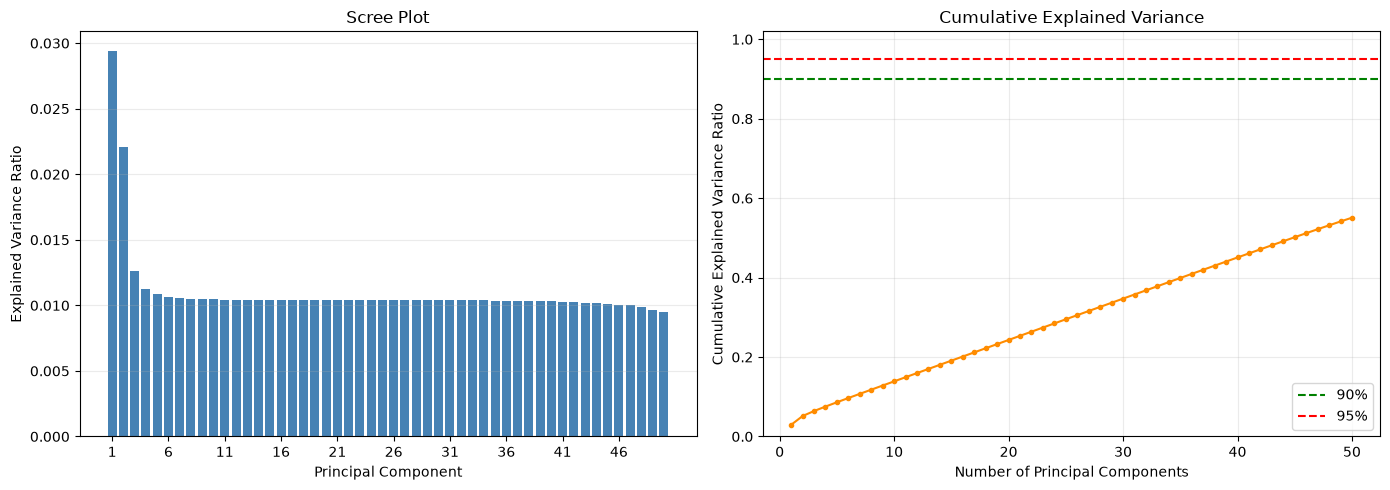

More than 50 components are needed to reach 90%; increase the component limit
More than 50 components are needed to reach 95%; increase the component limit


In [8]:
# Scree and cumulative explained variance plots
pc_numbers = np.arange(1, len(explained_variance) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(pc_numbers, explained_variance, color="steelblue")
axes[0].set_title("Scree Plot")
axes[0].set_xlabel("Principal Component")
axes[0].set_ylabel("Explained Variance Ratio")
axes[0].set_xticks(pc_numbers[::max(1, len(pc_numbers) // 10)])
axes[0].grid(axis="y", alpha=0.25)

axes[1].plot(pc_numbers, cumulative_variance, marker="o", markersize=3, color="darkorange")
axes[1].axhline(0.90, color="green", linestyle="--", label="90%")
axes[1].axhline(0.95, color="red", linestyle="--", label="95%")
axes[1].set_title("Cumulative Explained Variance")
axes[1].set_xlabel("Number of Principal Components")
axes[1].set_ylabel("Cumulative Explained Variance Ratio")
axes[1].set_ylim(0, 1.02)
axes[1].legend()
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()

# Suggested dimensions under common 90% and 95% variance targets.
for target in (0.90, 0.95):
    needed = int(np.searchsorted(cumulative_variance, target) + 1)
    if needed <= len(cumulative_variance):
        print(f"At least {needed} components are needed to reach {target:.0%} of variance")
    else:
        print(f"More than {len(cumulative_variance)} components are needed to reach {target:.0%}; increase the component limit")


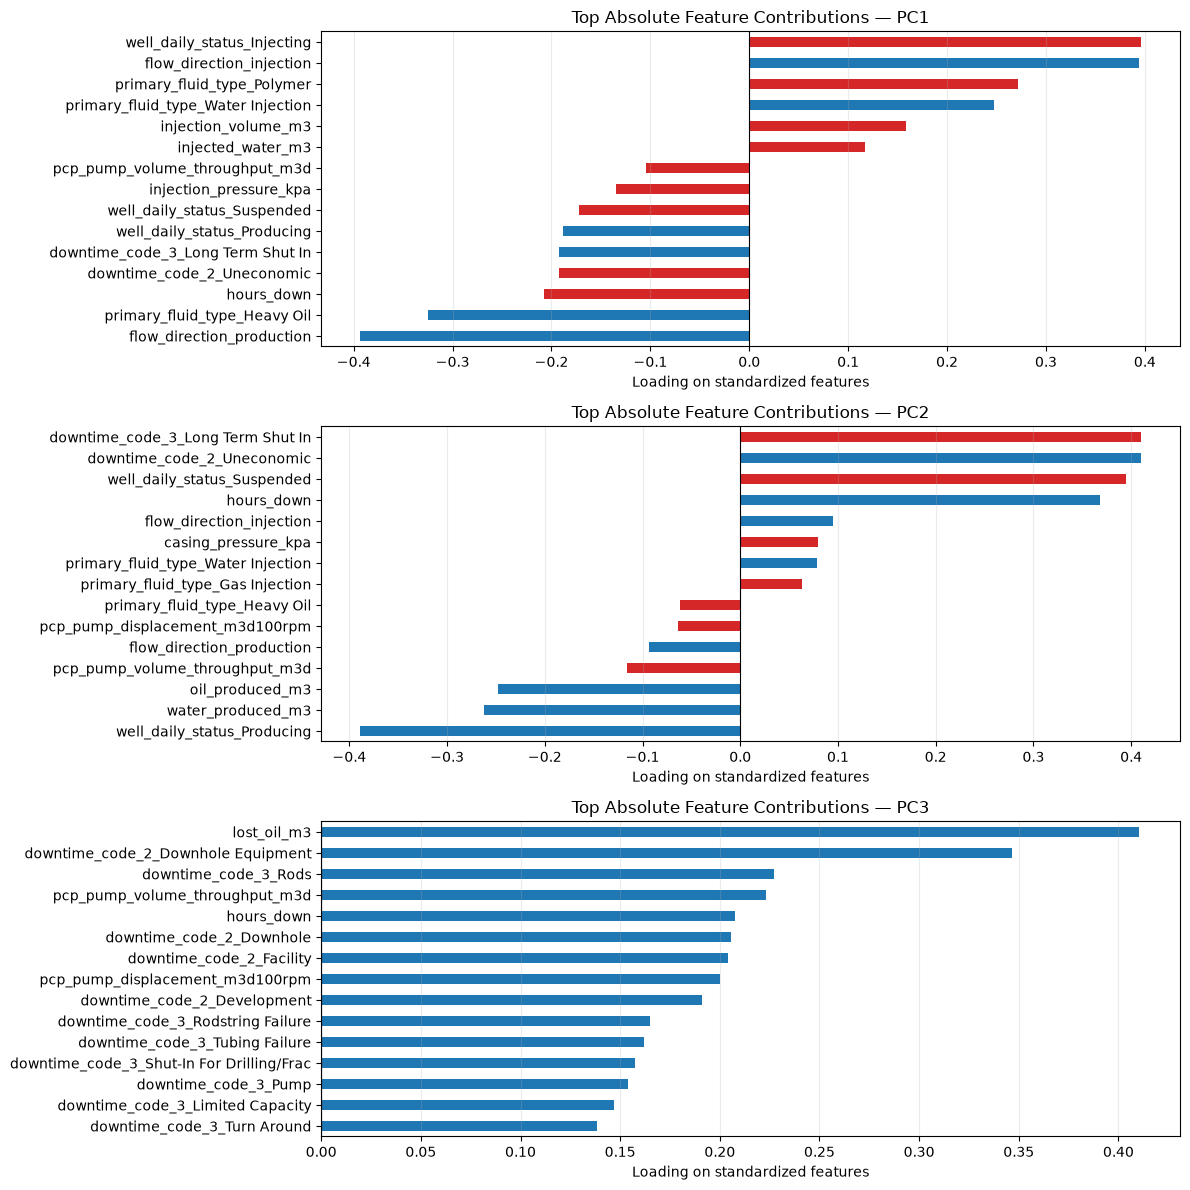


PC1 top absolute loadings


,feature,loading
0,well_daily_status_Injecting,0.396049
1,flow_direction_injection,0.394124
2,flow_direction_production,-0.393362
3,primary_fluid_type_Heavy Oil,-0.324587
4,primary_fluid_type_Polymer,0.271243
5,primary_fluid_type_Water Injection,0.247085
6,hours_down,-0.207767
7,downtime_code_2_Uneconomic,-0.192186
8,downtime_code_3_Long Term Shut In,-0.191987
9,well_daily_status_Producing,-0.188424



PC2 top absolute loadings


,feature,loading
0,downtime_code_3_Long Term Shut In,0.410022
1,downtime_code_2_Uneconomic,0.409828
2,well_daily_status_Suspended,0.394976
3,well_daily_status_Producing,-0.388810
4,hours_down,0.368229
5,water_produced_m3,-0.261836
6,oil_produced_m3,-0.247507
7,pcp_pump_volume_throughput_m3d,-0.115902
8,flow_direction_injection,0.094576
9,flow_direction_production,-0.093588



PC3 top absolute loadings


,feature,loading
0,lost_oil_m3,0.410371
1,downtime_code_2_Downhole Equipment,0.346551
2,downtime_code_3_Rods,0.227060
3,pcp_pump_volume_throughput_m3d,0.223001
4,hours_down,0.207525
5,downtime_code_2_Downhole,0.205585
6,downtime_code_2_Facility,0.204026
7,pcp_pump_displacement_m3d100rpm,0.199934
8,downtime_code_2_Development,0.191201
9,downtime_code_3_Rodstring Failure,0.164961


In [9]:
# PCA loadings show how strongly each standardized, numeric feature contributes to
# each principal component. Absolute loadings are used for ranking.
feature_names = pca_data.columns.to_numpy()
loadings = exploration_pca.components_.T

n_plot_components = min(3, loadings.shape[1])
fig, axes = plt.subplots(n_plot_components, 1, figsize=(12, 4 * n_plot_components))
if n_plot_components == 1:
    axes = [axes]

for pc_index, ax in enumerate(axes):
    pc_loadings = pd.Series(loadings[:, pc_index], index=feature_names)
    top_loadings = pc_loadings.reindex(pc_loadings.abs().sort_values(ascending=False).head(15).index)

    colors = ["tab:red" if value < 0 else "tab:blue" for value in top_loadings]
    top_loadings.sort_values().plot.barh(ax=ax, color=colors)
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_title(f"Top Absolute Feature Contributions — PC{pc_index + 1}")
    ax.set_xlabel("Loading on standardized features")
    ax.grid(axis="x", alpha=0.25)

plt.tight_layout()
plt.show()

# Compact ranking table for the first few PCs.
for pc_index in range(n_plot_components):
    ranking = pd.Series(loadings[:, pc_index], index=feature_names)
    print(f"\nPC{pc_index + 1} top absolute loadings")
    display(pd.DataFrame({
        "feature": ranking.abs().sort_values(ascending=False).head(15).index,
        "loading": ranking.loc[ranking.abs().sort_values(ascending=False).head(15).index].values,
    }))


Final PCA uses 50 components to reach approximately 95% variance
Final components explain 55.08% of variance


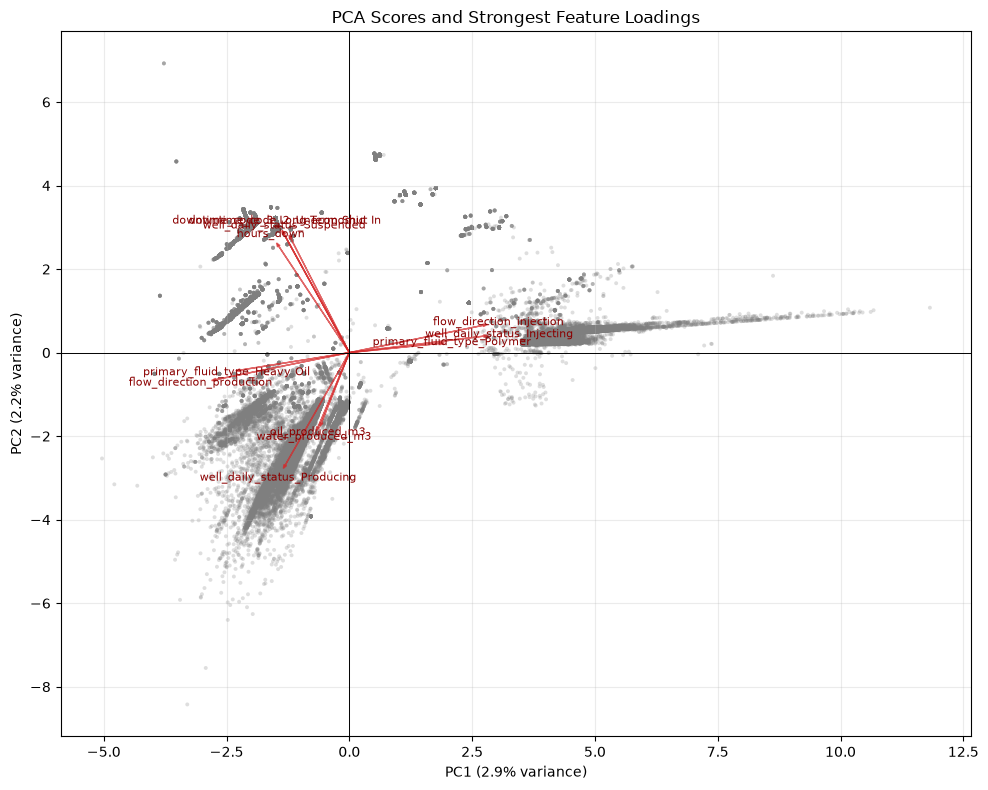

In [10]:
# Final PCA pipeline: preserve at least 95% of variance when the exploratory
# scree plot reaches that target. The integer component count is required by the
# randomized solver in this scikit-learn version.
components_for_95 = int(np.searchsorted(cumulative_variance, 0.95) + 1)
if components_for_95 > len(cumulative_variance):
    components_for_95 = len(cumulative_variance)

# To reuse it on the full dataframe: final_pca_pipeline.transform(pca_data)
final_pca_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("pca", PCA(
        n_components=components_for_95,
        svd_solver="randomized",
        random_state=42,
    )),
])

X_final_sample = final_pca_pipeline.fit_transform(analysis_sample)
final_pca = final_pca_pipeline.named_steps["pca"]

print(f"Final PCA uses {final_pca.n_components_} components to reach approximately 95% variance")
print(f"Final components explain {final_pca.explained_variance_ratio_.sum():.2%} of variance")

# PC1 vs PC2 biplot, showing only the strongest loading vectors.
pc1 = X_final_sample[:, 0]
pc2 = X_final_sample[:, 1]

fig, ax = plt.subplots(figsize=(10, 8))
ax.scatter(pc1, pc2, s=8, alpha=0.25, edgecolors="none", color="tab:gray")

# Scale loadings to the score range for legibility.
final_loadings = final_pca.components_.T
loadings_pc1 = final_loadings[:, 0]
loadings_pc2 = final_loadings[:, 1]
strongest = np.argsort(np.hypot(loadings_pc1, loadings_pc2))[-12:]
score_scale = max(np.std(pc1), np.std(pc2))

for column_index in strongest:
    dx = loadings_pc1[column_index] * score_scale * 3
    dy = loadings_pc2[column_index] * score_scale * 3
    ax.arrow(0, 0, dx, dy, head_width=score_scale * 0.025,
             length_includes_head=True, alpha=0.7, color="tab:red")
    ax.text(dx * 1.08, dy * 1.08, str(feature_names[column_index]),
            fontsize=8, ha="center", va="center", color="darkred")

ax.axhline(0, color="black", linewidth=0.7)
ax.axvline(0, color="black", linewidth=0.7)
ax.set_xlabel(f"PC1 ({final_pca.explained_variance_ratio_[0]:.1%} variance)")
ax.set_ylabel(f"PC2 ({final_pca.explained_variance_ratio_[1]:.1%} variance)")
ax.set_title("PCA Scores and Strongest Feature Loadings")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()
